In [2]:
import numpy as np

# Load the .npy file
#data = np.load("/work/h2020deciderficarra_shared/gcorso/suamin/giga_features/features_LUSC/TCGA-6A-AB49-01Z-00-DX1.FDF2EED7-57A3-4019-A382-21DED11780F6.npy", allow_pickle=True)


In [2]:
data

array([[ 1.0303631 , -0.6485348 ,  1.781991  , ...,  0.64579326,
        -1.3523366 ,  0.3386684 ],
       [ 0.78313494, -0.6663651 ,  0.7828582 , ..., -0.6024013 ,
        -0.75038785,  0.01964626],
       [ 0.84072334, -0.6901902 ,  0.98597956, ..., -0.68555987,
        -0.8332437 ,  0.43541715],
       ...,
       [ 0.5341943 , -0.20851822,  1.727284  , ..., -1.2186652 ,
         0.15866368, -0.3003992 ],
       [ 0.3418332 , -1.6631011 ,  0.03179257, ..., -0.7394327 ,
        -0.21822906,  0.40963364],
       [ 1.6409806 , -0.80237883,  1.407367  , ..., -0.9548204 ,
         0.4886974 ,  0.18229634]], dtype=float32)

In [1]:
import faiss

print(faiss.__version__)
print("GPU count:", faiss.get_num_gpus())


1.15.0
GPU count: 0


In [7]:
import faiss
import numpy as np
import pandas as pd

# Load FAISS index
index = faiss.read_index("output/kmeans/kmeans_faiss.index")

# Load cluster mapping
#mapping = np.load(
 #   "completeuni/LUSCcode/embedding_cluster_mapping.npz",
  #  allow_pickle=True
#)
mapping = pd.read_csv(
    "output/kmeans/embedding_cluster_mapping.csv"
)

# Extract stored data
labels = mapping["cluster"]
embedding_names = mapping["embedding_name"]
patch_metadata = mapping["patch_name"]

print("FAISS index loaded")
print("Number of clusters:", index.ntotal)

print("Labels shape:", labels.shape)
print("Embedding names:", len(embedding_names))
print("Metadata:", len(patch_metadata))

# Check one example
i = 4

print("\nExample:")
print("Embedding name:", embedding_names[i])
print("Cluster:", labels[i])
print("Metadata:", patch_metadata[i])

FAISS index loaded
Number of clusters: 5
Labels shape: (2308777,)
Embedding names: 2308777
Metadata: 2308777

Example:
Embedding name: _x_10672_y_14336.jpg
Cluster: 1
Metadata: _x_10672_y_14336.jpg


In [8]:
import numpy as np

unique, counts = np.unique(labels, return_counts=True)

for c, n in zip(unique, counts):
    print(f"Cluster {c}: {n} patches ({n/len(labels)*100:.2f}%)")

Cluster 0: 584000 patches (25.29%)
Cluster 1: 559004 patches (24.21%)
Cluster 2: 446575 patches (19.34%)
Cluster 3: 427015 patches (18.50%)
Cluster 4: 292183 patches (12.66%)


In [5]:
wsi_name = "TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234"

indices = [
    i for i,m in enumerate(patch_metadata)
    if m["wsi"] == wsi_name
]

print("Number of patches:", len(indices))

clusters = labels[indices]

for c, n in zip(*np.unique(clusters, return_counts=True)):
    print(f"Cluster {c}: {n}")

Number of patches: 0


In [303]:
import faiss
import numpy as np

index = faiss.read_index("completeuni/LUSCcode/kmeans_faiss.index")

#mapping = np.load(
 #   "completegiga/features_KIRC/output/kmeans/embedding_cluster_mapping.npz",
  #  allow_pickle=True
#)
mapping = pd.read_csv(
    "completegiga/LUSC/output/kmeans/embedding_cluster_mapping.csv"
)

labels = mapping["cluster"]

centers = index.reconstruct_n(0, index.ntotal)

print("Centers:", centers.shape)

Centers: (5, 1536)


In [304]:
import os, glob
import numpy as np

folder = "compeletegiga/features_KIRC/embedding"
files = sorted(glob.glob(folder + "/*.npy"))

# First pass: count rows
rows = 0
dim = None

for f in files:
    d = np.load(f, allow_pickle=True).item()
    x = d["features"]

    rows += x.shape[0]
    dim = x.shape[1]

print("Total:", rows, dim)

# Disk-backed array
out = np.memmap(
    "KIRP_normalized.dat",
    dtype="float32",
    mode="w+",
    shape=(rows, dim)
)

start = 0

for f in files:
    d = np.load(f, allow_pickle=True).item()
    x = d["features"].astype(np.float32)

    n = x.shape[0]

    # Normalize
    x /= np.maximum(
        np.linalg.norm(x, axis=1, keepdims=True),
        1e-12
    )

    out[start:start+n] = x
    start += n

    print(f, n)

out.flush()

print("Saved:", out.shape)


Total: 0 None


TypeError: unsupported operand type(s) for *: 'int' and 'NoneType'

In [3]:
X = np.memmap(
    "KIRP_normalized.dat",
    dtype="float32",
    mode="r",
    shape=(3476567, 1536)
)

print(X.shape)


OSError: [WinError 8] Not enough memory resources are available to process this command

In [15]:
inertia = 0
batch_size = 50000

# You need the normalized embeddings X for this
for start in range(0, X.shape[0], batch_size):

    batch = X[start:start+batch_size]
    batch_labels = labels[start:start+batch_size]

    batch_centers = centers[batch_labels]

    distances = np.sum(
        (batch - batch_centers) ** 2,
        axis=1
    )

    inertia += distances.sum()

print("KMeans inertia:", inertia)

KMeans inertia: 3.1465008e+06


In [16]:
from sklearn.metrics import silhouette_score

sample_size = 10000

idx = np.random.choice(
    len(labels),
    sample_size,
    replace=False
)

score = silhouette_score(
    X[idx],
    labels[idx]
)

print("Silhouette score:", score)

Silhouette score: 0.04016392305493355


In [5]:
import glob
import numpy as np

f = glob.glob("completeuni/KIRP/embedding/*.npy")[0]

d = np.load(f, allow_pickle=True).item()

print(d.keys())

for key, value in d.items():
    if hasattr(value, "shape"):
        print(key, value.shape)


dict_keys(['features', 'patch_names'])
features (8835, 1536)


X sample: (50000, 1536)
Labels: (50000,)


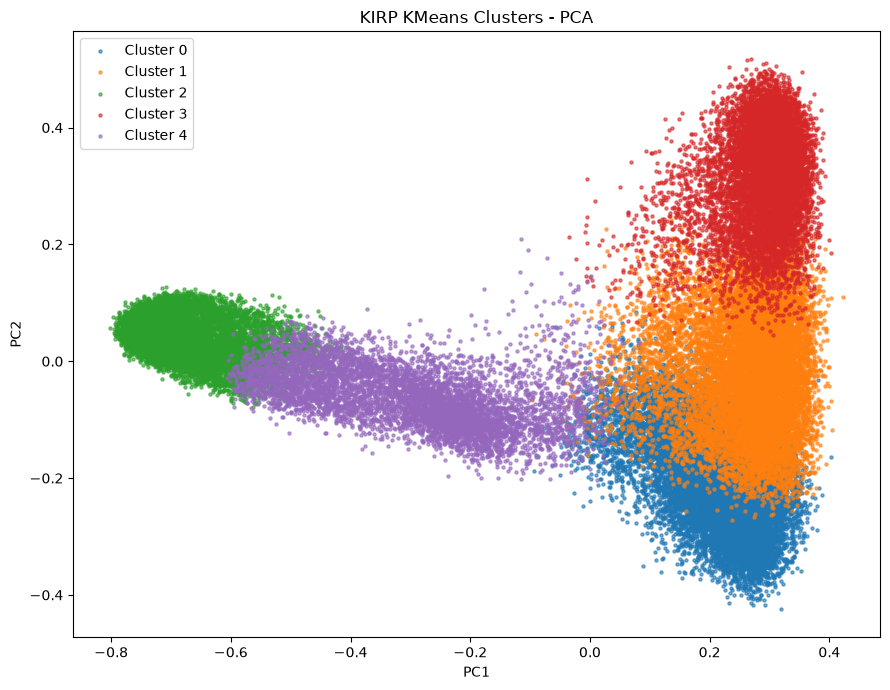

In [9]:
import glob
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

folder = "LUAD"
files = sorted(glob.glob(folder + "/*.npy"))

sample_size = 50000
rng = np.random.default_rng(42)

# Random indices from the COMPLETE dataset
idx = rng.choice(
    len(labels),
    min(sample_size, len(labels)),
    replace=False
)

idx.sort()

X_samples = []
label_samples = []

start = 0

for f in files:

    d = np.load(f, allow_pickle=True).item()
    X_file = d["features"].astype(np.float32)

    end = start + len(X_file)

    # Samples belonging to this file
    mask = (idx >= start) & (idx < end)

    if np.any(mask):

        local_idx = idx[mask] - start

        X_samples.append(X_file[local_idx])
        label_samples.append(labels[idx[mask]])

    start = end

X_sample = np.concatenate(X_samples)
labels_sample = np.concatenate(label_samples)

print("X sample:", X_sample.shape)
print("Labels:", labels_sample.shape)

# Normalize
X_sample /= np.maximum(
    np.linalg.norm(X_sample, axis=1, keepdims=True),
    1e-12
)

# PCA
pca = PCA(n_components=2, random_state=42)

X_2d = pca.fit_transform(X_sample)

# Plot clusters
plt.figure(figsize=(9, 7))

for c in np.unique(labels_sample):

    mask = labels_sample == c

    plt.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        s=5,
        alpha=0.6,
        label=f"Cluster {c}"
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("KIRP KMeans Clusters - PCA")
plt.legend()
plt.tight_layout()
plt.show()


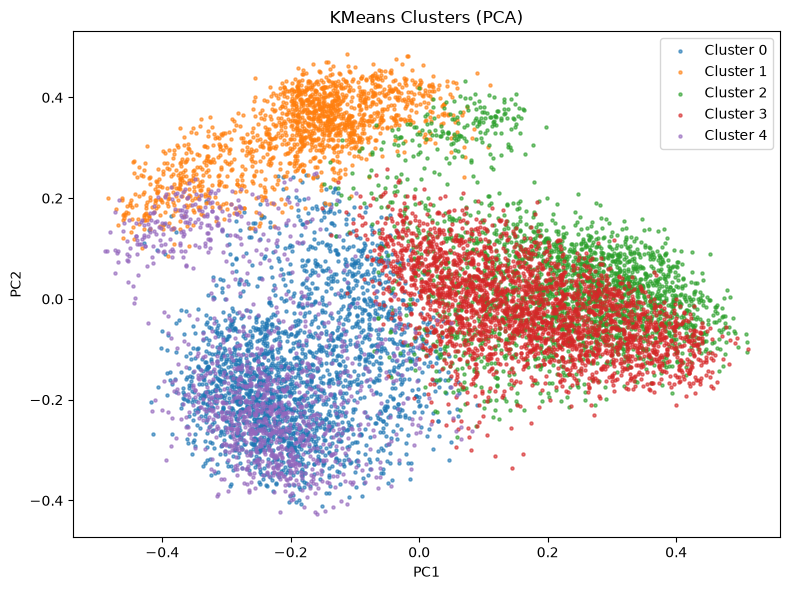

In [17]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# Randomly sample points (don't plot all 3M)
sample_size = 10000

idx = np.random.choice(len(labels), sample_size, replace=False)

X_sample = X[idx]
labels_sample = labels[idx]

# Reduce to 2D
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_sample)

# Plot
plt.figure(figsize=(8, 6))

for c in np.unique(labels_sample):
    mask = labels_sample == c
    plt.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        s=5,
        alpha=0.6,
        label=f"Cluster {c}"
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("KMeans Clusters (PCA)")
plt.legend()
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
data= np.load("/homes/suamin/Bioinformatics_project/LUSCcode/embedding_cluster_mapping.npz", allow_pickle=True)


In [2]:
print(data.files)

['labels', 'embedding_names', 'patch_metadata']


In [3]:
data

NpzFile '/homes/suamin/Bioinformatics_project/LUSCcode/embedding_cluster_mapping.npz' with keys: labels, embedding_names, patch_metadata

In [5]:
patch_metadata = data["patch_metadata"]

print(type(patch_metadata))
print(patch_metadata.dtype)
print(patch_metadata.shape)
print(type(patch_metadata[0]))
print(patch_metadata[100])

<class 'numpy.ndarray'>
object
(3080719,)
<class 'dict'>
{'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch': 100, 'patch_name': '_x_76800_y_66560.jpg'}


In [261]:
cluster_0 = []
cluster_1 = []
cluster_2 = []
cluster_3 = []
cluster_4 = []

In [295]:
# import numpy as np

# # Load the npz
# data = np.load("completegiga/Features_LUAD/output/kmeans/embedding_cluster_mapping.npz", allow_pickle=True)

# labels = data["labels"]                # (3080719,)
# embedding_names = data["embedding_names"]
# metadata = data["patch_metadata"]

# # Find indices where cluster == 0
# cluster_id = 0
# idx = np.where(labels == cluster_id)[0]

# print(f"Number of samples in cluster {cluster_id}: {len(idx)}")

# # Extract corresponding data
# cluster_names = embedding_names[idx]
# cluster_metadata = metadata[idx]

# # Example
# for name, meta in zip(cluster_names[:5], cluster_metadata[:5]):
#     print(name)
#     print(meta)
#     print("-" * 50)

import pandas as pd

# Load the CSV
data = pd.read_csv(
    "completegiga/LUSC/output/kmeans/embedding_cluster_mapping.csv"
)

# Find rows where cluster == 0
cluster_id = 4
cluster_data = data[data["cluster"] == cluster_id]

print(f"Number of samples in cluster {cluster_id}: {len(cluster_data)}")

# Extract corresponding data
cluster_names = cluster_data["embedding_name"].values

# Create metadata in the same format expected by your second code
cluster_metadata = cluster_data[["wsi", "patch_name"]].to_dict("records")

# Example
for name, meta in zip(cluster_names[:5], cluster_metadata[:5]):
    print(name)
    print(meta)
    print("-" * 50)


Number of samples in cluster 4: 764730
_x_100352_y_10240.jpg
{'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_10240.jpg'}
--------------------------------------------------
_x_100352_y_11264.jpg
{'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_11264.jpg'}
--------------------------------------------------
_x_100352_y_12288.jpg
{'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_12288.jpg'}
--------------------------------------------------
_x_100352_y_13312.jpg
{'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_13312.jpg'}
--------------------------------------------------
_x_100352_y_14336.jpg
{'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_14336.jpg'}
--------------------------------------------------


In [296]:
patch_names = [[ m["wsi"],m["patch_name"]] for m in cluster_metadata]


In [297]:
import os
import ast
import re
from tqdm import tqdm

txt_dir = "completeuni/LUSCcode/ClusterCellType"

results = []

# Cache parsed txt files so we don't repeatedly read the same file
wsi_cache = {}

for meta in tqdm(cluster_metadata):
    wsi = meta["wsi"]
    patch_name = meta["patch_name"]

    # Parse txt only once per WSI
    if wsi not in wsi_cache:
        txt_path = os.path.join(txt_dir, f"{wsi}.txt")

        patch_dict = {}

        if os.path.exists(txt_path):
            with open(txt_path, "r") as f:
                text = f.read()

            # Match:
            # _x_101376_y_36864.jpg:
            # {'Neoplastic': 2, 'Connective': 32}
            matches = re.findall(
                r'(_x_\d+_y_\d+\.jpg):\s*\n(\{.*?\})',
                text,
                flags=re.DOTALL
            )

            for p_name, info in matches:
                patch_dict[p_name] = ast.literal_eval(info)

        wsi_cache[wsi] = patch_dict

    info = wsi_cache[wsi].get(patch_name)

    results.append({
        "wsi": wsi,
        "patch_name": patch_name,
        "info": info
    })

print(f"Collected {len(results)} entries.")
print(results[:5])


100%|██████████| 764730/764730 [00:28<00:00, 26447.87it/s]

Collected 764730 entries.
[{'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_10240.jpg', 'info': {'Inflammatory': 93, 'Connective': 115, 'Neoplastic': 2}}, {'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_11264.jpg', 'info': {'Inflammatory': 17, 'Connective': 31}}, {'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_12288.jpg', 'info': {'Connective': 160, 'Inflammatory': 5}}, {'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_13312.jpg', 'info': {'Connective': 104, 'Inflammatory': 4}}, {'wsi': 'TCGA-18-3406-01Z-00-DX1.8D07F006-425C-4724-BBB3-5BA099401234', 'patch_name': '_x_100352_y_14336.jpg', 'info': {'Connective': 6, 'Inflammatory': 1}}]


In [298]:
from collections import Counter

cell_type_counts = Counter()

missing = 0

for item in results:
    info = item["info"]

    if info is None:
        missing += 1
        continue

    # Add the counts for each cell type
    cell_type_counts.update(info)

print("Total cell counts in this cluster:")
print("-" * 40)

for cell_type, count in cell_type_counts.most_common():
    print(f"{cell_type:20s}: {count:,}")

print("-" * 40)
print(f"Patches with missing info: {missing}")


Total cell counts in this cluster:
----------------------------------------
Connective          : 98,546,154
Inflammatory        : 65,595,993
Neoplastic          : 23,773,391
Epithelial          : 2,577,533
Dead                : 1,727,750
----------------------------------------
Patches with missing info: 12238


In [299]:
total_cells = sum(cell_type_counts.values())
total = f"\nTotal cells in cluster: {total_cells:,}\n"

for cell_type, count in cell_type_counts.most_common():
    pct = 100 * count / total_cells
    type = f"{cell_type:20s}: {count:8,d} ({pct:5.2f}%)"
    cluster_4.append(type)



In [300]:
import pandas as pd

clusters = [cluster_0, cluster_1, cluster_2, cluster_3, cluster_4]

data = {}

for i, cluster in enumerate(clusters):
    values = {}

    for line in cluster:
        # Cell type is before the colon
        cell_type = line.split(":")[0].strip()

        # Percentage is between '(' and '%)'
        percentage = float(line.split("(")[1].replace("%)", "").strip())

        values[cell_type] = percentage

    data[f"Cluster {i}"] = values

df = pd.DataFrame(data)

print(df)


              Cluster 0  Cluster 1  Cluster 2  Cluster 3  Cluster 4
Connective        48.40      27.80      32.38      45.19      51.27
Inflammatory      25.60      19.32      19.47      29.51      34.13
Neoplastic        21.46      50.63      44.48      23.03      12.37
Epithelial         3.05       1.00       2.06       1.08       1.34
Dead               1.48       1.25       1.61       1.20       0.90


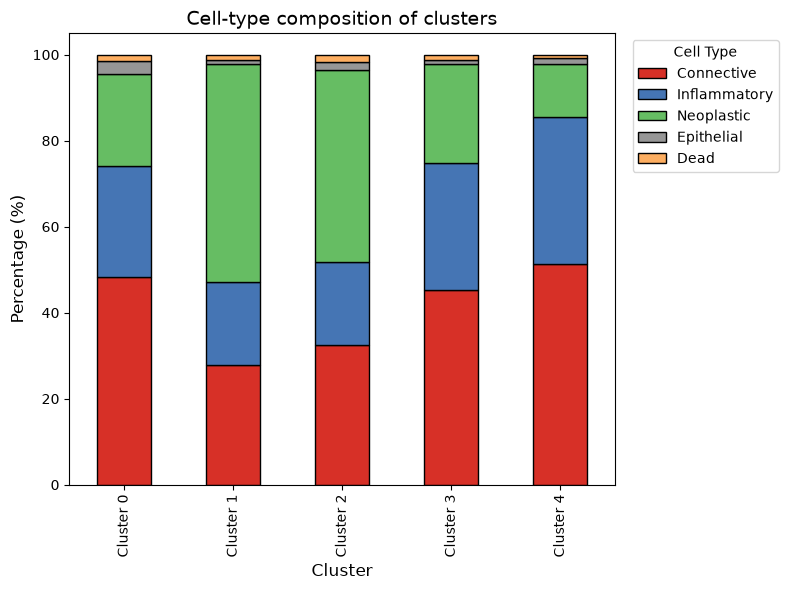

In [301]:
import matplotlib.pyplot as plt

colors = [
    "#d73027",  # Inflammatory
    "#4575b4",  # Connective
    "#66bd63",  # Neoplastic
    "#969696",  # Dead
    "#fdae61",  # Epithelial
]

ax = df.T.plot(
    kind="bar",
    stacked=True,
    figsize=(8,6),
    color=colors,
    edgecolor="black",
)

ax.set_ylabel("Percentage (%)", fontsize=12)
ax.set_xlabel("Cluster", fontsize=12)
ax.set_title("Cell-type composition of clusters", fontsize=14)

ax.legend(
    title="Cell Type",
    bbox_to_anchor=(1.02,1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


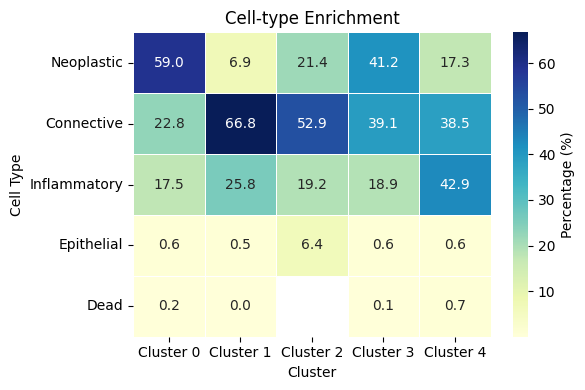

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

sns.heatmap(
    df,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label":"Percentage (%)"}
)

plt.title("Cell-type Enrichment")
plt.xlabel("Cluster")
plt.ylabel("Cell Type")

plt.tight_layout()
plt.show()
